## Notebook 02 — Exploratory Data Analysis (EDA)

### Purpose
Explore the cleaned Dataset 1 to understand distributions, patterns, and relationships before modelling. All plots generated here will be saved to `outputs/figures/`.
### Input
`data/processed/D1_cleaned_readable.csv` — cleaned D1 with original text columns (human-readable)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')
FIGURES_PATH = '../outputs/figures/'

df = pd.read_csv('../data/processed/D1_cleaned_readable.csv', low_memory=False)

# Parse dates
date_cols = ['InitialDateReported', 'MostRecentDateReported', 'DiscontinuedDate', 'ChemicalCreatedAt', 'ChemicalUpdatedAt']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print(f"Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFlagProp65:\n{df['FlagProp65'].value_counts()}")

Shape: (63212, 29)

Columns: ['CDPHId', 'ProductName', 'CompanyId', 'CompanyName', 'BrandName', 'PrimaryCategoryId', 'PrimaryCategory', 'SubCategoryId', 'SubCategory', 'CasId', 'CasNumber', 'ChemicalId', 'ChemicalName', 'InitialDateReported', 'MostRecentDateReported', 'DiscontinuedDate', 'ChemicalCreatedAt', 'ChemicalUpdatedAt', 'ChemicalCount', 'InitialYear', 'FlagHighRisk', 'FlagCleanMarketed', 'CAS_norm', 'FlagProp65', 'IsTradeSecret', 'IsDiscontinued', 'DaysSinceReported', 'WasUpdated', 'ReportingSpanDays']

FlagProp65:
FlagProp65
False    59815
True      3397
Name: count, dtype: int64


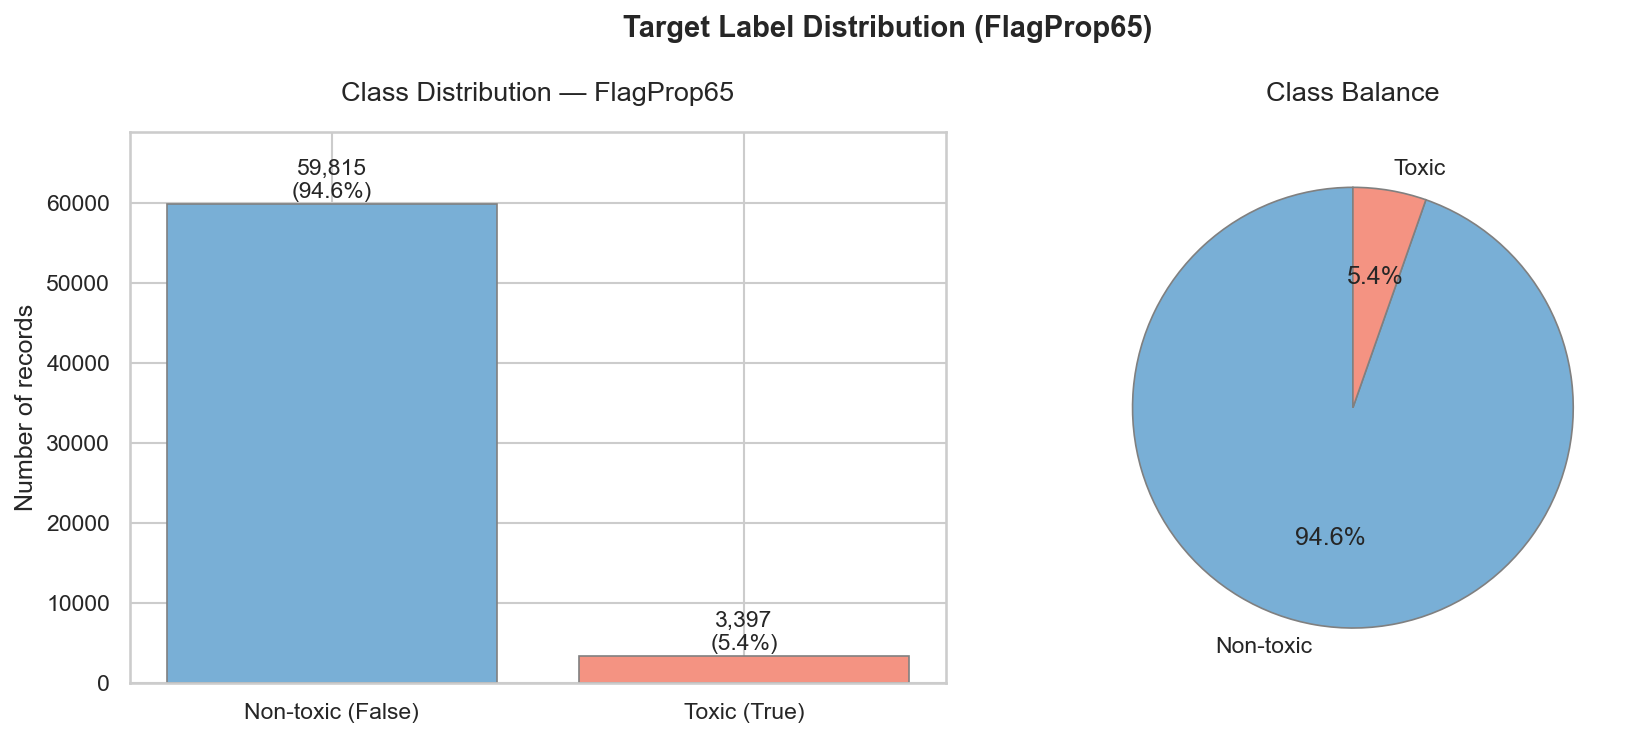

Saved: 01_class_distribution.png


In [9]:
# === THESIS COLOR PALETTE (use these for every plot) ===
COLOR_NONTOXIC = "#79AFD6"
COLOR_TOXIC = "#F49382"
COLOR_PALETTE = [COLOR_NONTOXIC, COLOR_TOXIC]

# === PLOT 1 REDONE: Class distribution ===
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

counts = df['FlagProp65'].value_counts()

# Bar chart
axes[0].bar(['Non-toxic (False)', 'Toxic (True)'], counts.values,
            color=COLOR_PALETTE, edgecolor='grey', linewidth=0.8)
axes[0].set_title('Class Distribution — FlagProp65', fontsize=13, pad=15)
axes[0].set_ylabel('Number of records')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 800, f'{v:,}\n({v/len(df)*100:.1f}%)',
                ha='center', fontsize=11)
axes[0].set_ylim(0, max(counts.values) * 1.15)  # extra space at top

# Pie chart
axes[1].pie(counts.values, labels=['Non-toxic', 'Toxic'],
            colors=COLOR_PALETTE,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'grey', 'linewidth': 0.8})
axes[1].set_title('Class Balance', fontsize=13, pad=15)

plt.suptitle('Target Label Distribution (FlagProp65)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_PATH + '01_class_distribution.png', bbox_inches='tight')
plt.show()
print("Saved: 01_class_distribution.png")

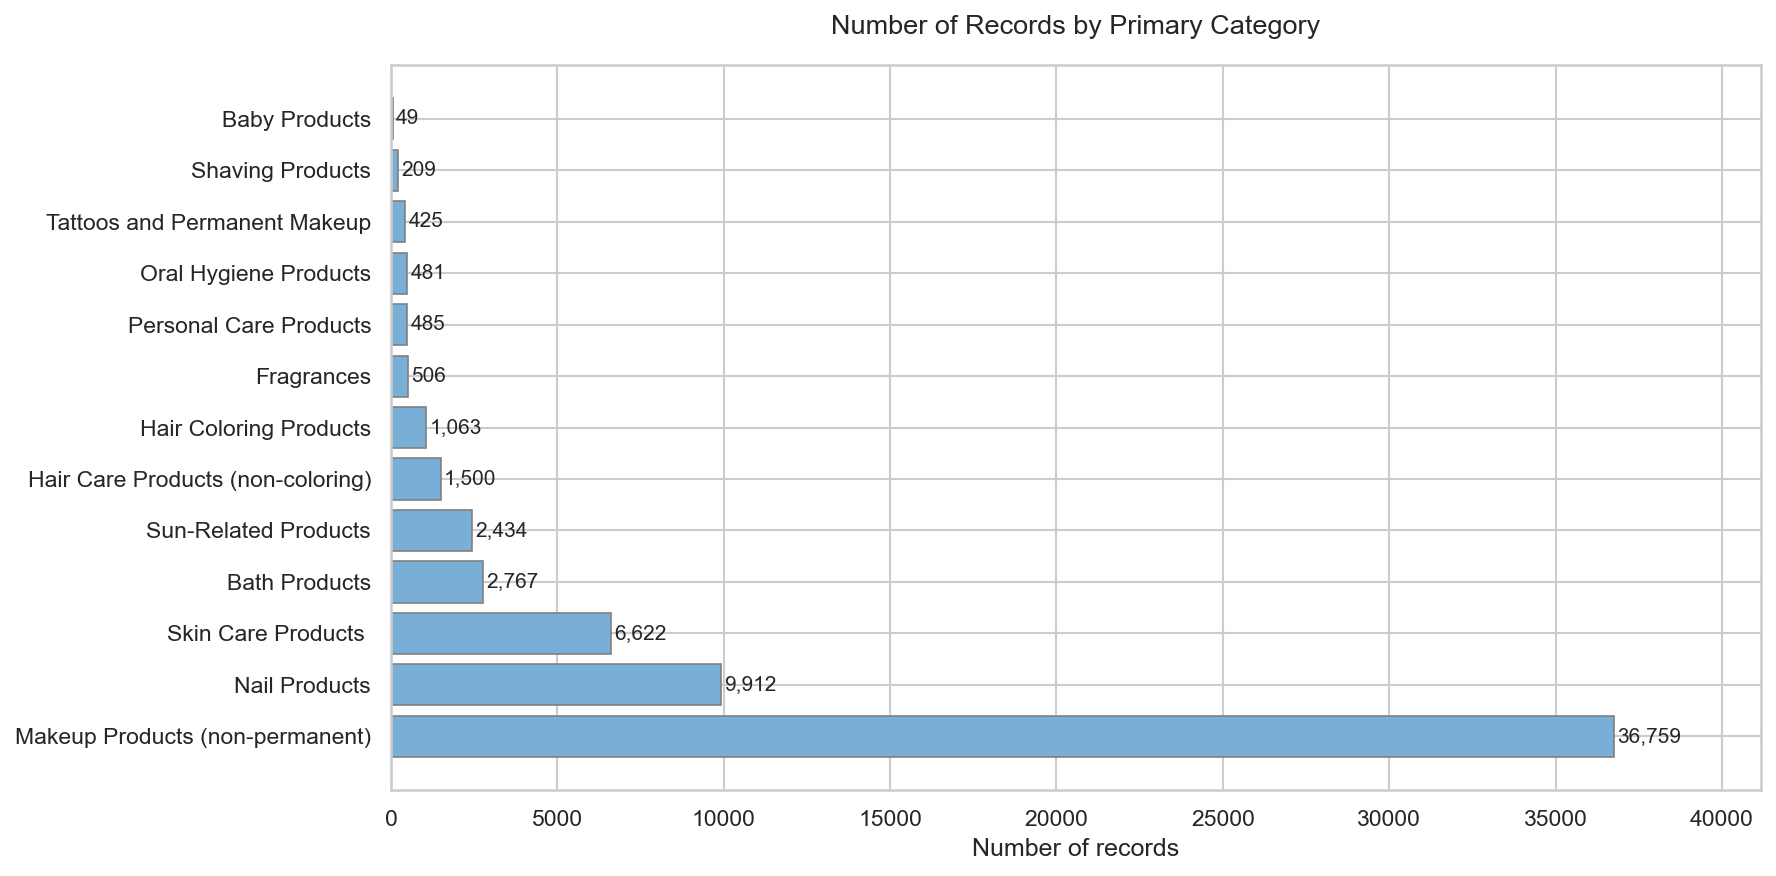

Saved: 02_records_by_category.png


In [11]:
# === PLOT 2: Records by Primary Category ===
cat_counts = df['PrimaryCategory'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(cat_counts.index, cat_counts.values, 
               color='#79AFD6', edgecolor='grey', linewidth=0.8)

# Add value labels
for bar, val in zip(bars, cat_counts.values):
    ax.text(val + 100, bar.get_y() + bar.get_height()/2, f'{val:,}', va='center', fontsize=10)

ax.set_title('Number of Records by Primary Category', fontsize=13, pad=15)
ax.set_xlabel('Number of records')
ax.set_xlim(0, cat_counts.values.max() * 1.12)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '02_records_by_category.png', bbox_inches='tight')
plt.show()
print("Saved: 02_records_by_category.png")

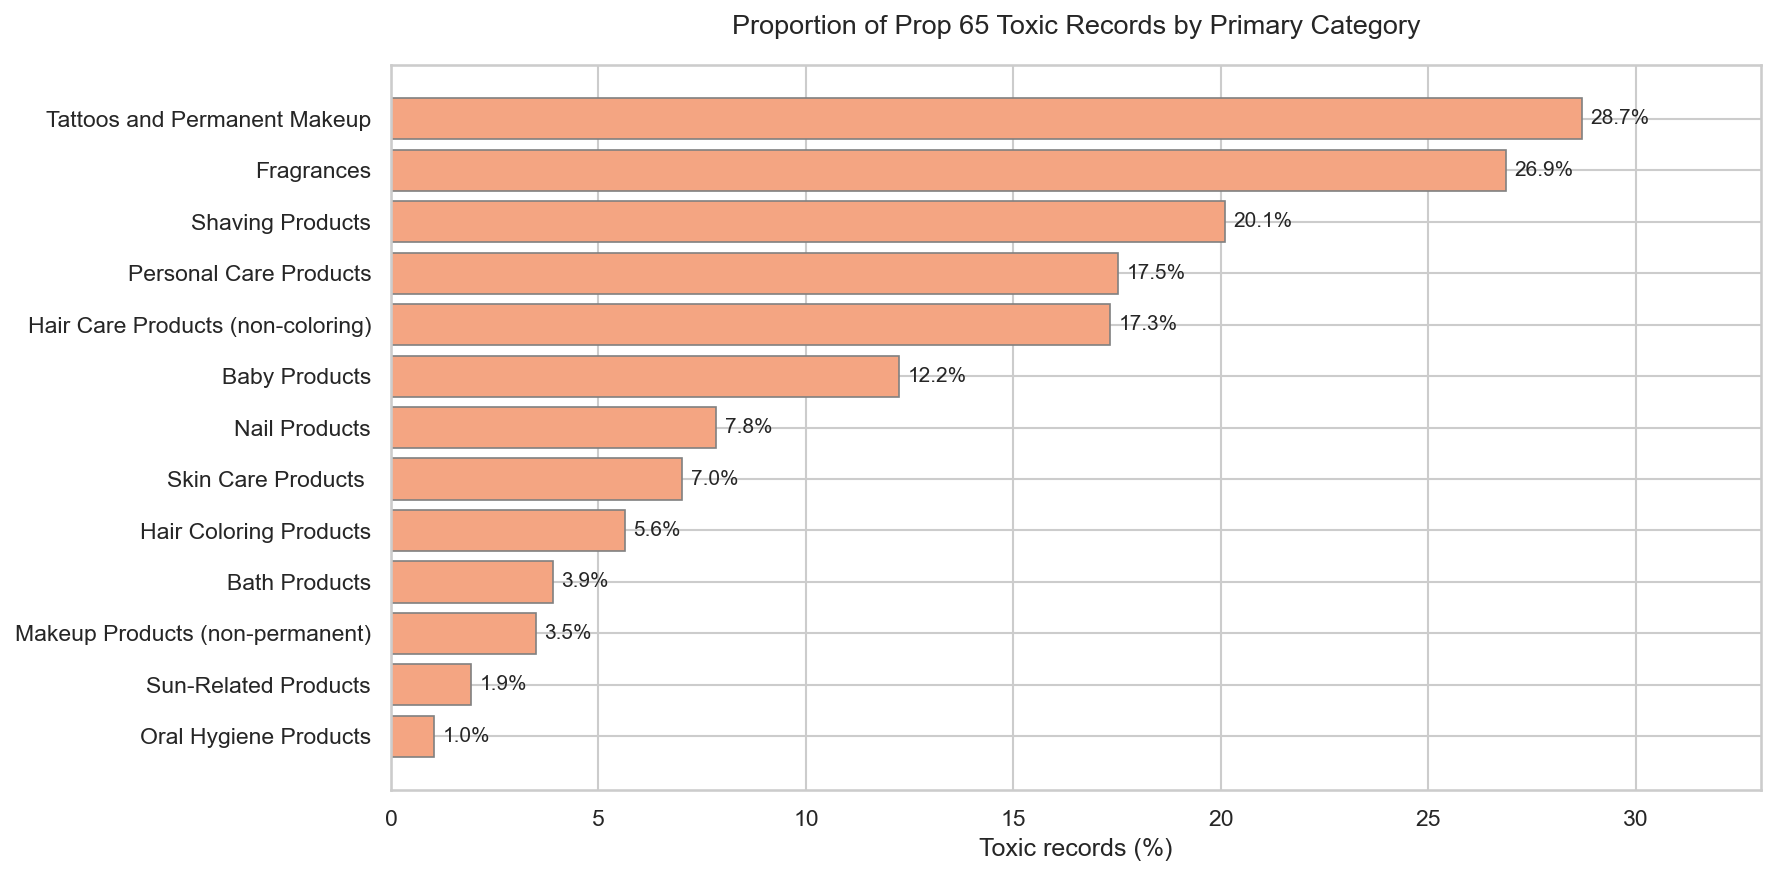

Saved: 03_toxic_rate_by_category.png


In [12]:
# === PLOT 3: Toxic rate by Primary Category ===
toxic_rate = df.groupby('PrimaryCategory')['FlagProp65'].mean().sort_values(ascending=True) * 100

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(toxic_rate.index, toxic_rate.values,
               color='#F4A582', edgecolor='grey', linewidth=0.8)

for bar, val in zip(bars, toxic_rate.values):
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=10)

ax.set_title('Proportion of Prop 65 Toxic Records by Primary Category', fontsize=13, pad=15)
ax.set_xlabel('Toxic records (%)')
ax.set_xlim(0, toxic_rate.values.max() * 1.15)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '03_toxic_rate_by_category.png', bbox_inches='tight')
plt.show()
print("Saved: 03_toxic_rate_by_category.png")

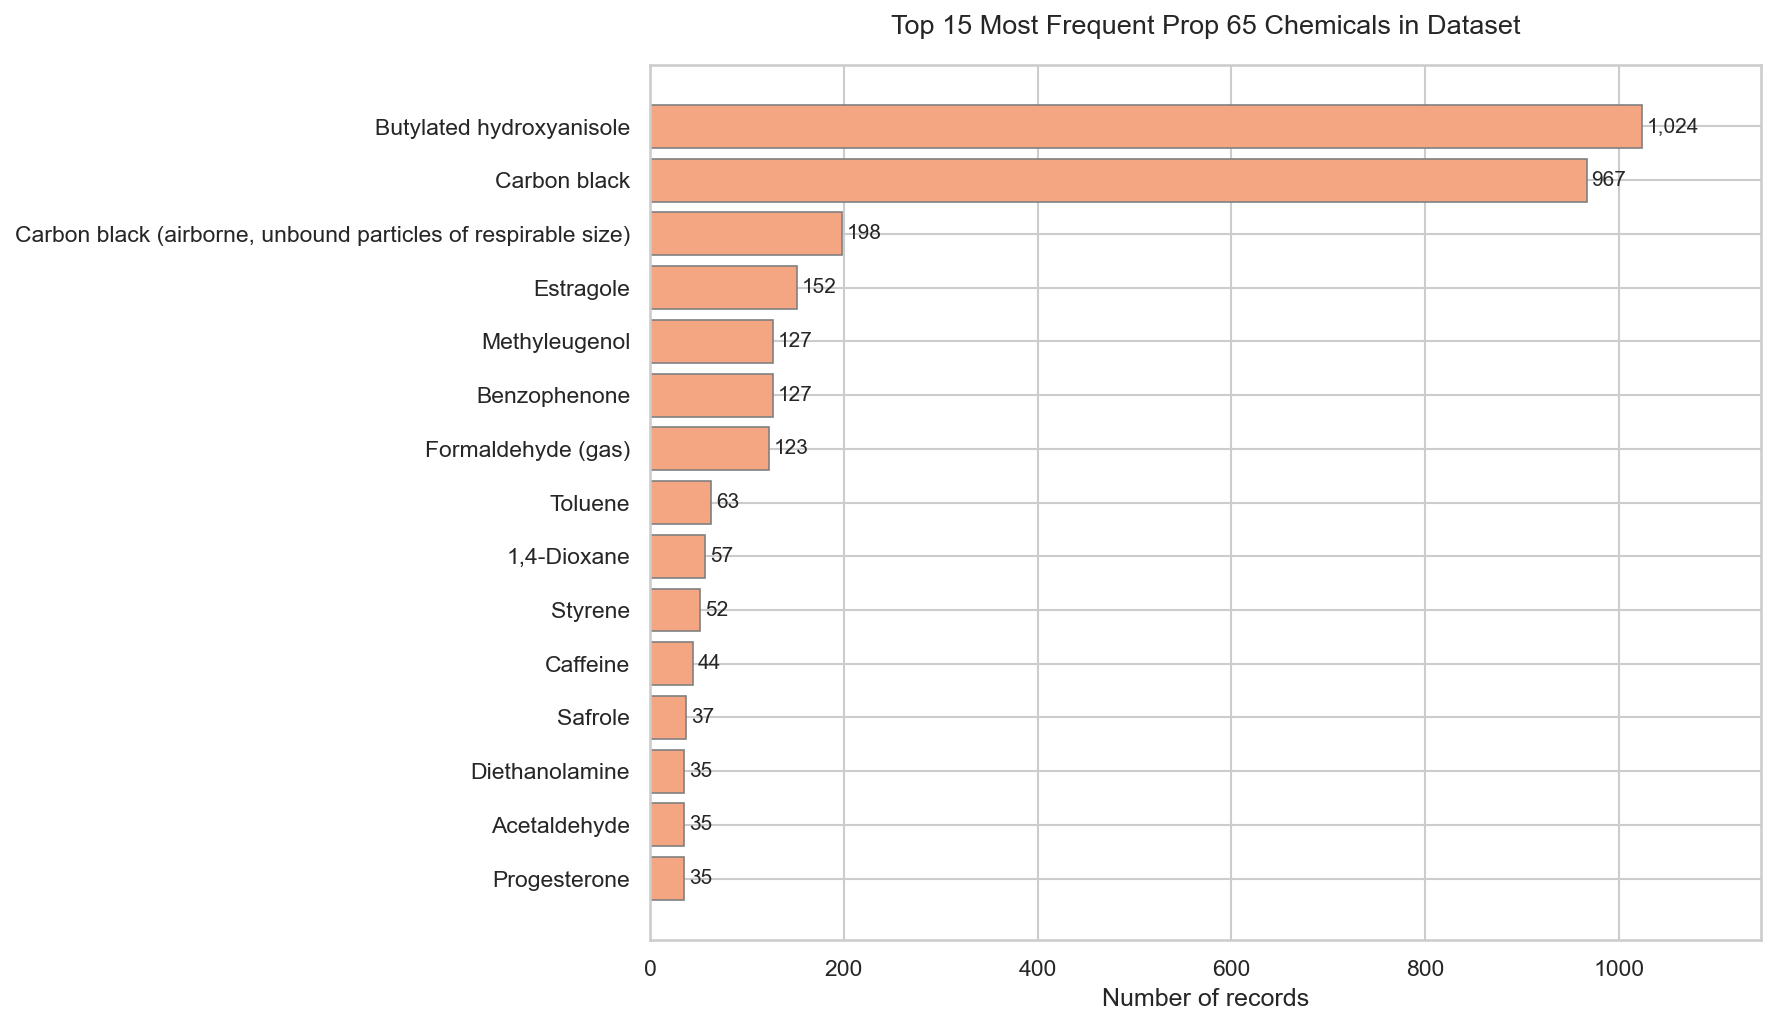

Saved: 04_top_toxic_chemicals.png


In [13]:
# === PLOT 4: Top 15 most frequent toxic chemicals ===
toxic_chemicals = df[df['FlagProp65'] == True]['ChemicalName'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(toxic_chemicals.index[::-1], toxic_chemicals.values[::-1],
               color='#F4A582', edgecolor='grey', linewidth=0.8)

for bar, val in zip(bars, toxic_chemicals.values[::-1]):
    ax.text(val + 5, bar.get_y() + bar.get_height()/2, f'{val:,}', va='center', fontsize=10)

ax.set_title('Top 15 Most Frequent Prop 65 Chemicals in Dataset', fontsize=13, pad=15)
ax.set_xlabel('Number of records')
ax.set_xlim(0, toxic_chemicals.values.max() * 1.12)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '04_top_toxic_chemicals.png', bbox_inches='tight')
plt.show()
print("Saved: 04_top_toxic_chemicals.png")

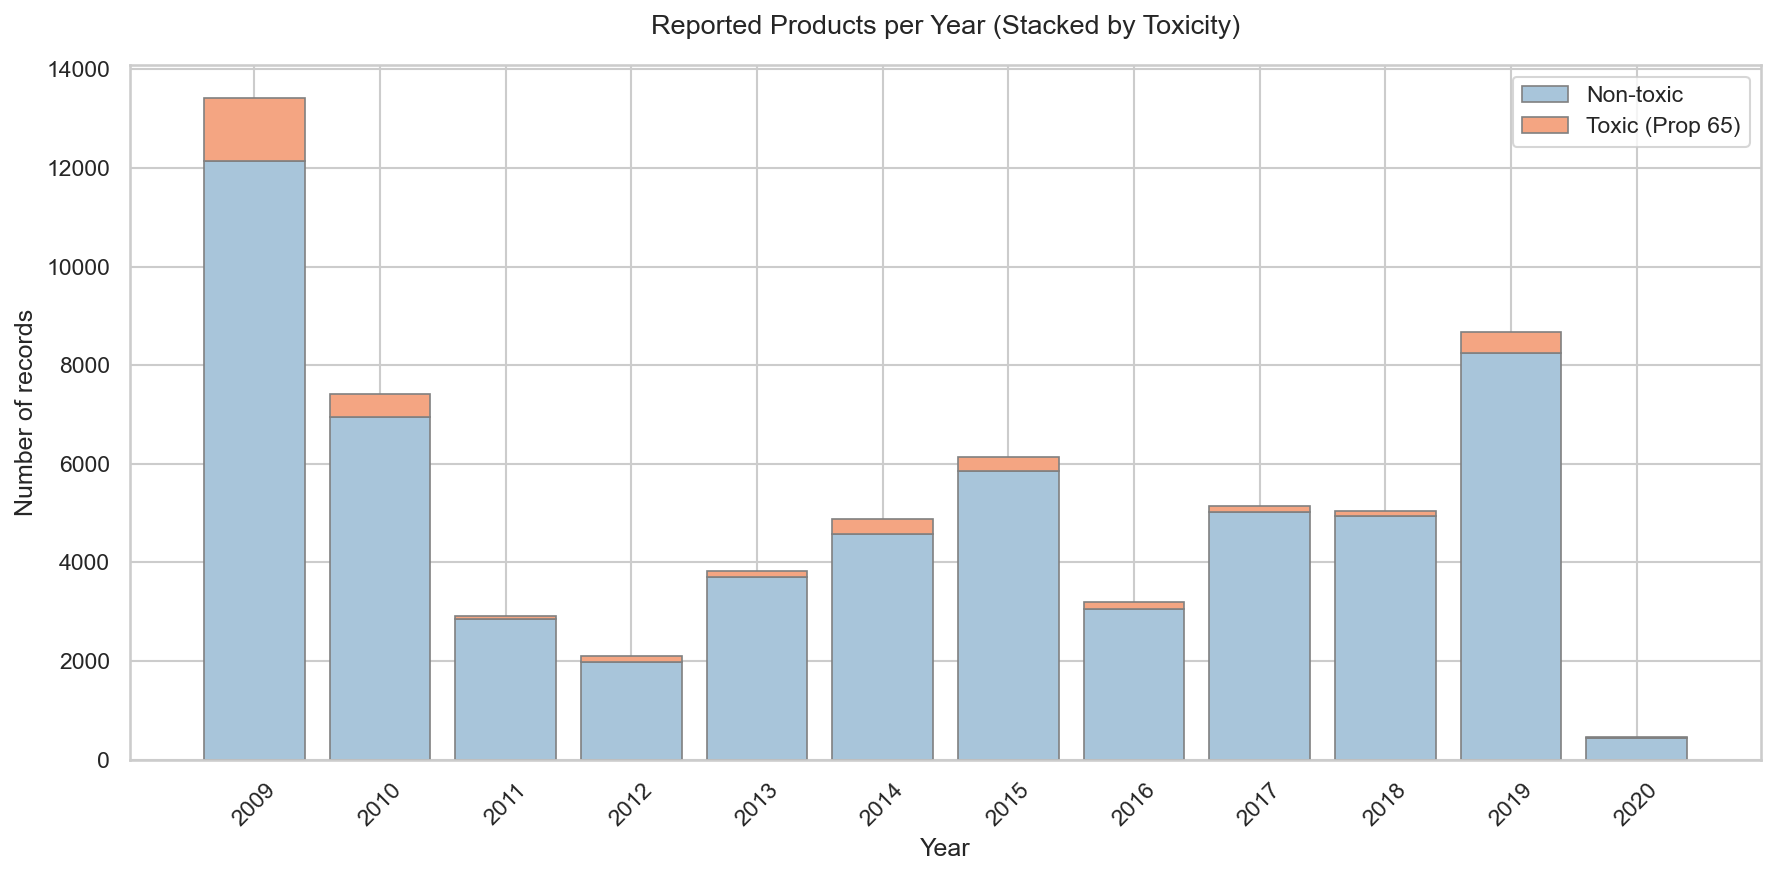

Saved: 05_reporting_trends_over_time.png


In [14]:
# === PLOT 5: Reporting trends over time ===
yearly = df.groupby('InitialYear').agg(
    total=('FlagProp65', 'count'),
    toxic=('FlagProp65', 'sum')
).reset_index()
yearly['nontoxic'] = yearly['total'] - yearly['toxic']

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(yearly['InitialYear'], yearly['nontoxic'], 
       label='Non-toxic', color='#A8C5DA', edgecolor='grey', linewidth=0.8)
ax.bar(yearly['InitialYear'], yearly['toxic'], 
       bottom=yearly['nontoxic'],
       label='Toxic (Prop 65)', color='#F4A582', edgecolor='grey', linewidth=0.8)

ax.set_title('Reported Products per Year (Stacked by Toxicity)', fontsize=13, pad=15)
ax.set_xlabel('Year')
ax.set_ylabel('Number of records')
ax.legend()
ax.set_xticks(yearly['InitialYear'])
ax.set_xticklabels(yearly['InitialYear'], rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '05_reporting_trends_over_time.png', bbox_inches='tight')
plt.show()
print("Saved: 05_reporting_trends_over_time.png")

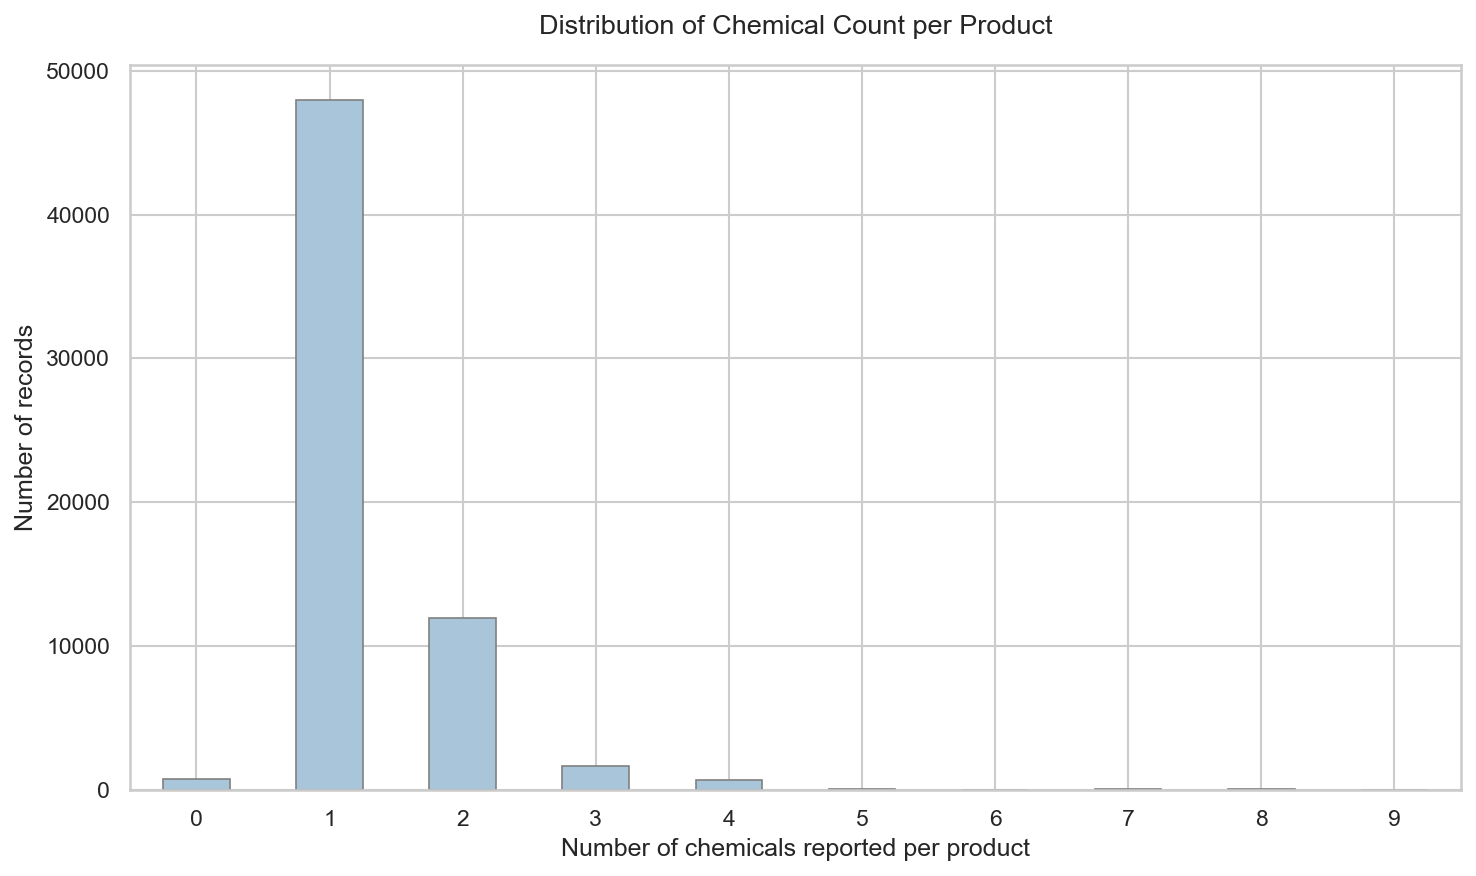

Saved: 06_chemical_count_distribution.png


In [15]:
# === PLOT 6: Chemical count per product ===
fig, ax = plt.subplots(figsize=(10, 6))

df['ChemicalCount'].value_counts().sort_index().plot(
    kind='bar', ax=ax, color='#A8C5DA', edgecolor='grey', linewidth=0.8)

ax.set_title('Distribution of Chemical Count per Product', fontsize=13, pad=15)
ax.set_xlabel('Number of chemicals reported per product')
ax.set_ylabel('Number of records')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '06_chemical_count_distribution.png', bbox_inches='tight')
plt.show()
print("Saved: 06_chemical_count_distribution.png")

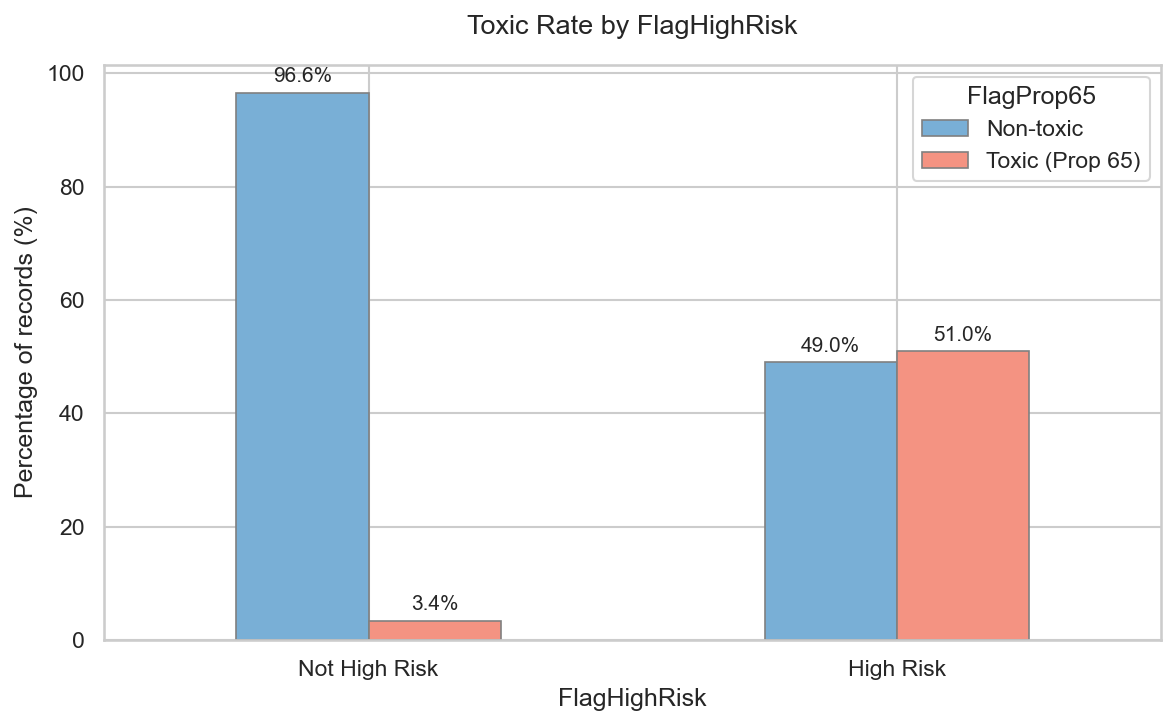

Saved: 07_highrisk_vs_prop65.png


In [16]:
# === PLOT 7: FlagHighRisk vs FlagProp65 ===
crosstab = pd.crosstab(df['FlagHighRisk'], df['FlagProp65'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(8, 5))
crosstab.plot(kind='bar', ax=ax, color=COLOR_PALETTE, edgecolor='grey', linewidth=0.8, width=0.5)

ax.set_title('Toxic Rate by FlagHighRisk', fontsize=13, pad=15)
ax.set_xlabel('FlagHighRisk')
ax.set_ylabel('Percentage of records (%)')
ax.set_xticklabels(['Not High Risk', 'High Risk'], rotation=0)
ax.legend(['Non-toxic', 'Toxic (Prop 65)'], title='FlagProp65')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_PATH + '07_highrisk_vs_prop65.png', bbox_inches='tight')
plt.show()
print("Saved: 07_highrisk_vs_prop65.png")

When FlagHighRisk = True, 51% of products are Prop 65 toxic — basically a coin flip. When FlagHighRisk = False, only 3.4% are toxic. This tells us FlagHighRisk will likely be one of the most important features in your model.

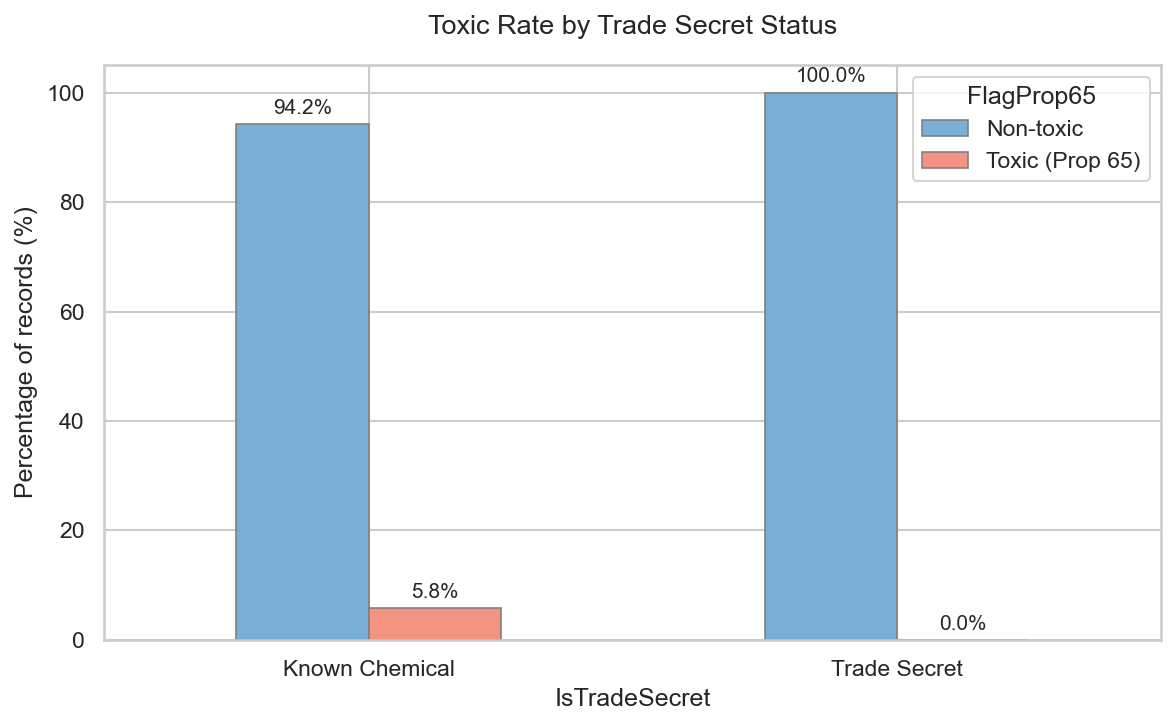

Saved: 08_tradesecret_vs_prop65.png


In [17]:
# === PLOT 8: Trade secret vs toxic rate ===
crosstab2 = pd.crosstab(df['IsTradeSecret'], df['FlagProp65'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(8, 5))
crosstab2.plot(kind='bar', ax=ax, color=COLOR_PALETTE,
               edgecolor='grey', linewidth=0.8, width=0.5)

ax.set_title('Toxic Rate by Trade Secret Status', fontsize=13, pad=15)
ax.set_xlabel('IsTradeSecret')
ax.set_ylabel('Percentage of records (%)')
ax.set_xticklabels(['Known Chemical', 'Trade Secret'], rotation=0)
ax.legend(['Non-toxic', 'Toxic (Prop 65)'], title='FlagProp65')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_PATH + '08_tradesecret_vs_prop65.png', bbox_inches='tight')
plt.show()
print("Saved: 08_tradesecret_vs_prop65.png")

Trade secret chemicals show 0% Prop 65 toxic rate — which seems counterintuitive since companies hide ingredients specifically to protect formulas.
FlagProp65 is assigned by matching the CAS number against the Prop 65 list. Trade secret rows have no CAS number, so they can never match — the 0% is a labeling artifact, not a real finding. - important to mention in the thesis as a limitation of the labeling approach - The graph says “trade secret chemicals are 100% non-toxic” but that’s misleading. It doesn’t mean they’re safe — it means we couldn’t check. Some of those hidden chemicals might actually be on the Prop 65 list, we just have no way to know.
- model will learn that IsTradeSecret = 1 means non-toxic, which is wrong — it just means unknown

- CAS stands for Chemical Abstracts Service — it’s a unique identification number assigned to every known chemical substance, like an ID card for chemicals.  
For example:  
Water → 7732-18-5  
Titanium dioxide → 13463-67-7  
Carbon black → 1333-86-4  

Every chemical in the world has one. They’re used universally in science, regulation, and industry because chemical names can vary — the same substance might be called different things by different companies or in different languages, but the CAS number is always the same.